# Mini Project — Build a RAG System for Your Own Data
### IT7075: Applied AI for Cybersecurity · Retrieval-Augmented Generation

The first half of this notebook is the lecture pipeline with five pieces left for you to write, one per
step of the RAG recipe you saw in class:

| | Step | You write |
|---|---|---|
| **TODO 1** | chunk the documents | 3 lines |
| **TODO 2** | embed and store them in ChromaDB | 2 lines |
| **TODO 3** | retrieve the closest chunks | 3 lines |
| **TODO 4** | augment the prompt with what you retrieved | 2 lines |
| **TODO 5** | measure whether the answer was actually found | 4 lines |

Everything else is already written. Each TODO is marked like this, so you can find them by
searching for `###################`:

```
###################  TODO n — title  ###################
# what to do, and how
################
```

The five TODOs are practice on the course documents. After them, from Part 6 onward, no code is
provided: you build a RAG for data you create yourself, run your own experiments, and write it up in a
report and a video. Read `MiniProject_RAG.md` for the deliverables and the rubric.

> **Runs offline.** No API key needed. The generate step uses one if you have it, and otherwise
> prints an offline answer so the pipeline still works end to end.

## Part 1 — Chunk the documents  ·  **TODO 1**

The first few lines import what you need and load the embedding model — nothing to change there.
Then comes your first piece of code.

You cannot embed a whole document as one vector — one vector cannot represent ten topics. So you
cut each document into overlapping chunks, exactly as in Lecture 2. The **overlap** keeps a
sentence that lands on a boundary from being lost to both chunks.

> **Expected output:** `ssrf.txt -> 11 chunks`, `cybersecurity_kb.md -> 11 chunks`, **22 total**.

In [1]:
# If needed:  !pip install -q sentence-transformers chromadb pandas matplotlib openai
import json, os
import pandas as pd
import matplotlib.pyplot as plt

# Keep this notebook on the CPU. The model here is tiny (milliseconds either way),
# and this avoids the "CUDA error: no kernel image is available" failure -- or a very
# long hang while torch initialises -- on a machine whose PyTorch build does not match
# its GPU. This must run BEFORE anything imports torch.
os.environ.setdefault("CUDA_VISIBLE_DEVICES", "")

from sentence_transformers import SentenceTransformer
import chromadb

# ---- the documents that came with the course -----------------------------
def kb_path(name):
    """The course files live in RAG/code/. Works from this folder or solutions/."""
    p = "../../code/" + name
    return p if os.path.exists(p) else "../../../code/" + name

import glob
COURSE_KB = ["course_files/ssrf.txt", "course_files/cybersecurity_kb.md"]
GOLDSET_FILE = "course_files/baseline_goldset.json"

# ---- ONE embedding model, used for BOTH the chunks and the questions -----
embedder = SentenceTransformer("all-MiniLM-L6-v2")     # 384 numbers per text, runs locally

def embed(texts):
    return embedder.encode(texts, normalize_embeddings=True).tolist()


###################  TODO 1 — cut a document into overlapping chunks  ###################
# WHAT: finish split_into_chunks() so it returns a list of text pieces.
#
# HOW (this is the Lecture 2 chunking cell):
#   * piece  = chunk_size characters of `text`, starting at `start`, with .strip()
#              applied so you don't keep leading/trailing whitespace
#   * append the piece to `pieces`, but ONLY if it is not an empty string
#   * move `start` forward by (chunk_size - overlap) -- NOT by chunk_size,
#     because the two chunks are supposed to share `overlap` characters
#
# WATCH OUT: if you move `start` forward by chunk_size you get no overlap at all;
#            if you forget to move it, the loop never ends.
################

def split_into_chunks(text, chunk_size=600, overlap=100):
    pieces = []
    start = 0
    while start < len(text):
        piece = text[start:start + chunk_size].strip()
        if piece:
            pieces.append(piece)
        start = start + (chunk_size - overlap)
    return pieces


# ---- given: apply it to both course documents ---------------------------
def load_and_chunk(files, chunk_size=600, overlap=100):
    """Read every file, chunk it, and remember which file each chunk came from."""
    chunks, sources = [], []
    for path in files:
        text = open(path, encoding="utf-8").read()
        pieces = split_into_chunks(text, chunk_size, overlap)
        chunks += pieces
        sources += [os.path.basename(path)] * len(pieces)
        print("  %-24s -> %2d chunks" % (os.path.basename(path), len(pieces)))
    return chunks, sources

chunks, sources = load_and_chunk(COURSE_KB)
print("  TOTAL:", len(chunks), "chunks")
print("\nFirst chunk starts:", chunks[0][:70])

/Users/benbesunder/rag_project/your-repo/RAG-Mini-Project/RAG-Mini-Project/rag_project/.venv/lib/python3.9/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


  ssrf.txt                 -> 11 chunks
  cybersecurity_kb.md      -> 11 chunks
  TOTAL: 22 chunks

First chunk starts: Server-Side Request Forgery Prevention Cheat Sheet
Introduction
The ob


## Part 2 — Embed and store in ChromaDB  ·  **TODO 2**

Now turn every chunk into a vector and put it in the vector database, as in Lecture 2. The
collection is created for you with `cosine` distance — Chroma's default is a different metric, and
every threshold in this notebook assumes cosine.

> **Expected output:** `Stored 22 chunks`.

In [2]:
client = chromadb.EphemeralClient()
_counter = [0]

def build_collection(chunks, sources):
    """Given: make a NEW empty collection using cosine distance, then fill it."""
    _counter[0] += 1                     # a fresh name each time, so re-running
    name = "kb_%d" % _counter[0]         # never mixes old chunks with new ones
    collection = client.get_or_create_collection(name, metadata={"hnsw:space": "cosine"})

    ###################  TODO 2 — put the chunks in the database  ###################
    # WHAT: give collection.add() the two arguments it is still missing.
    #
    # HOW (the Lecture 2 "operate ChromaDB" cell):
    #   * embeddings = the vectors for `chunks`. Use the embed() helper from
    #     Part 1 -- the SAME model must embed the chunks and, later, the question,
    #     or the distances mean nothing.
    #   * metadatas  = one small dict per chunk recording where it came from:
    #                  [{"source": s} for s in sources]
    #                  This is what lets an answer cite a file.
    ################

    collection.add(ids=["c%d" % i for i in range(len(chunks))],
                   documents=chunks,
                   embeddings=embed(chunks),
                   metadatas=[{"source": s} for s in sources])
    return collection


collection = build_collection(chunks, sources)
print("Stored", collection.count(), "chunks")

Stored 22 chunks


## Part 3 — Retrieve  ·  **TODO 3**

Embed the question with the same model, ask the database for the `k` closest chunks, and throw
away anything farther than `max_distance`.

That last step is the one people skip, and it matters: without it the database **always** returns
`k` chunks no matter how irrelevant, so your bot will happily answer a question your documents
never covered. An empty result is a *good* result — Part 4 turns it into "I don't know".

> **Expected output:** 4 hits for the SSRF question with distances around 0.36–0.43, and
> **0 hits** for "What is the capital of France?".

In [3]:
###################  TODO 3 — find the closest chunks  ###################
# WHAT: finish retrieve() so it returns a list of hits, closest first.
#       Each hit is a dict: {"text": ..., "distance": ..., "source": ...}
#
# HOW (the Lecture 3 retrieve cell):
#   * query the collection with the EMBEDDED question and n_results=k:
#         results = collection.query(query_embeddings=embed([question]), n_results=k)
#   * Chroma wraps its answer in a list (one entry per question, and we asked one),
#     so the pieces you want are:
#         results["documents"][0]   results["distances"][0]   results["metadatas"][0]
#   * keep a hit only when its distance <= max_distance
#
# REMEMBER: cosine distance, so SMALL = similar. 0.0 is identical, 1.0 is unrelated.
################

def retrieve(collection, question, k=4, max_distance=0.75):
    results = collection.query(query_embeddings=embed([question]), n_results=k)

    hits = []
    for doc, dist, meta in zip(results["documents"][0],
                               results["distances"][0],
                               results["metadatas"][0]):
        if dist <= max_distance:
            hits.append({"text": doc, "distance": dist, "source": meta["source"]})
    return hits


# ---- given: try it on a question the documents answer, and one they don't
for q in ["Is SSRF limited to HTTP, or can other protocols be involved?",
          "What is the capital of France?"]:
    found = retrieve(collection, q)
    print("Q:", q)
    print("   hits:", len(found))
    for h in found:
        print("     distance %.3f  [%s]  %s..." % (h["distance"], h["source"],
                                                   h["text"][:60].replace("\n", " ")))
    print()

Q: Is SSRF limited to HTTP, or can other protocols be involved?
   hits: 4
     distance 0.356  [ssrf.txt]  ed, and if poorly handled, can perform specific injection at...
     distance 0.399  [ssrf.txt]  teract with the internal/external network or the machine its...
     distance 0.405  [ssrf.txt]  ed to perform an SSRF attack. Take a look at the XXE cheat s...
     distance 0.431  [ssrf.txt]  ill be based on the following information:  String containin...

Q: What is the capital of France?
   hits: 0



## Part 4 — Augment the prompt and generate  ·  **TODO 4**

Augmentation is just building a string: paste the retrieved chunks into the prompt and tell the
model to answer from them only. `generate()` and `ask()` are written for you.

> **Expected output:** the SSRF question comes back tagged `[RAG]`; the Log4Shell question comes
> back tagged `[LLM]` with no context — the honest refusal from Lecture 3.

In [4]:
SYSTEM = (
    "You are a cybersecurity assistant. Answer the question using ONLY the context below.\n"
    "Cite the source file for every claim, like [ssrf.txt]. If the answer is in the context, start "
    "your reply with [RAG]. If the context is empty or does not contain the answer, say you do not "
    "know and start with [LLM] -- do not answer from memory.\n\n# Context\n{context}"
)

###################  TODO 4 — build the context block  ###################
# WHAT: finish build_context() so it turns a list of hits into ONE string.
#
# Format each hit like this, so the answer can be traced back to a file:
#
#     [1] (source: ssrf.txt)
#     <the chunk text>
#
#     [2] (source: cybersecurity_kb.md)
#     <the chunk text>
#
# HOW:
#   * loop over hits with  enumerate(hits, start=1)  so the numbering starts at 1
#   * build each block as  "[%d] (source: %s)\n%s" % (i, h["source"], h["text"])
#   * join the blocks with a BLANK LINE between them:  "\n\n".join(blocks)
#
# IMPORTANT: return "" when hits is empty. That empty string is what triggers the
#            [LLM] refusal path below -- do not return "no results" text instead.
################

def build_context(hits):
    if not hits:
        return ""
    blocks = []
    for i, h in enumerate(hits, start=1):
        blocks.append("[%d] (source: %s)\n%s" % (i, h["source"], h["text"]))
    return "\n\n".join(blocks)


# ---- given: generate an answer, then the whole pipeline in one function --
_USE_API = [True]      # set to False after one failure, so we don't retry a dead key

def generate(system, user):
    """Uses an LLM if one is available; otherwise quotes the context so this runs offline.

    The API call is guarded: if your key is missing, expired, or out of credit, the
    notebook prints one short note and keeps going in offline mode. Retrieval,
    scoring, and the whole tuning experiment do not need an LLM at all.
    """
    if os.getenv("OPENAI_API_KEY") and _USE_API[0]:
        try:
            from openai import OpenAI
            r = OpenAI().chat.completions.create(
                model="gpt-4o-mini", temperature=0,
                messages=[{"role": "system", "content": system},
                          {"role": "user", "content": user}])
            return r.choices[0].message.content
        except Exception as e:
            _USE_API[0] = False
            print("   (LLM unavailable - %s. Switching to offline mode for the rest of the"
                  " notebook; nothing in this project needs an LLM.)" % type(e).__name__)

    context = system.split("# Context\n", 1)[-1]
    if context.strip() == "" or context.strip() == "(nothing found)":
        return "[LLM] I don't know -- the documents do not cover this. (offline mode)"
    return "[RAG] (offline mode) From the retrieved context:\n" + context[:300]


def ask(collection, question, k=4, max_distance=0.75, show=True):
    """The complete RAG pipeline: retrieve -> augment -> generate."""
    hits = retrieve(collection, question, k, max_distance)
    context = build_context(hits)
    system = SYSTEM.format(context=context if context else "(nothing found)")
    answer = generate(system, question)
    if show:
        print("Q:", question)
        print("   grounded?", "YES, %d chunk(s)" % len(hits) if hits else "NO, nothing retrieved")
        print("   answer:", answer[:300].replace("\n", "\n           "), "\n")
    return {"hits": hits, "answer": answer}


_ = ask(collection, "What are the two basic cases in which SSRF can happen?")
_ = ask(collection, "What CVSS score did Log4Shell receive?")     # not in the documents

Q: What are the two basic cases in which SSRF can happen?
   grounded? YES, 4 chunk(s)
   answer: [RAG] (offline mode) From the retrieved context:
           [1] (source: ssrf.txt)
           ed to perform an SSRF attack. Take a look at the XXE cheat sheet to learn how to prevent exposure to XXE.
           Cases
           Depending on the application’s functionality and requirements, there are two basic cases in which SSRF can happen:
           
            

Q: What CVSS score did Log4Shell receive?
   grounded? NO, nothing retrieved
   answer: [LLM] I don't know -- the documents do not cover this. (offline mode) 



## Part 5 — Measure it  ·  **TODO 5**

To say one setting is better than another you need a number. `baseline_goldset.json` has **8
questions** about the course documents: **6 the documents answer** (each with the exact `evidence`
wording that proves it) and **2 they do not**.

Two counts, and that is all:

- **found** — of the 6 answerable questions, how many retrieved a chunk containing the evidence?
- **refused** — of the 2 unanswerable ones, how many correctly retrieved *nothing*?

> **Expected output at the Lecture 3 settings (k=4, threshold 0.75): found 6/6, refused 2/2.**

In [5]:
GOLDSET = json.load(open(GOLDSET_FILE))["questions"]
print("Loaded", len(GOLDSET), "questions\n")

###################  TODO 5 — score one configuration  ###################
# WHAT: finish score() so it counts `found` and `refused`.
#
# For each question q in the gold set, retrieve() is already called for you.
# Then:
#   * if q["answerable"] is True:
#       - the question counts as FOUND when ANY retrieved hit contains ANY of the
#         phrases in q["evidence"]. Compare in lower case, because the documents
#         are not consistently capitalised:
#             phrase.lower() in hit["text"].lower()
#       - a small helper, found_evidence(hits, q["evidence"]), is started for you
#   * if q["answerable"] is False:
#       - it counts as REFUSED when len(hits) == 0 -- nothing was retrieved
#
# WHY only these two numbers: `found` tells you whether the right text reached the
# model, and `refused` tells you whether the bot keeps quiet when it should. A
# setting that improves one while wrecking the other is not an improvement.
################

def found_evidence(hits, evidence):
    for h in hits:
        for phrase in evidence:
            if phrase.lower() in h["text"].lower():
                return True
    return False


def score(collection, goldset, k=4, max_distance=0.75):
    found, refused = 0, 0
    for q in goldset:
        hits = retrieve(collection, q["question"], k, max_distance)
        if q["answerable"]:
            if found_evidence(hits, q["evidence"]):
                found += 1
        else:
            if len(hits) == 0:
                refused += 1
    return found, refused


n_answerable = sum(q["answerable"] for q in GOLDSET)
n_unanswerable = len(GOLDSET) - n_answerable

found, refused = score(collection, GOLDSET)
print("found   %d/%d answerable questions" % (found, n_answerable))
print("refused %d/%d unanswerable questions" % (refused, n_unanswerable))

Loaded 8 questions

found   6/6 answerable questions
refused 2/2 unanswerable questions


## Part 6: from here on, the code is yours

Everything above ran on the course documents, and it was practice: the same pipeline you saw in the
lectures, one piece at a time. The rest of this notebook is a RAG for your own data, and no code is
provided for it. Reuse anything you wrote in Parts 1 to 5, adapt code from the lecture notebooks, or
write something different. What matters is that it works on your data and that you can explain it.

Add cells below that do all of the following:

1. Load your documents from `my_kb/` and report how many documents and how many characters you have.
2. Load your questions from `goldset.json`, and check that every evidence phrase really appears in your
   documents exactly as written. If one does not, your own results will report a miss that is not real.
3. Chunk, embed, and store your documents.
4. Answer your questions and print the transcript, including at least one question your documents cannot
   answer, so that the refusal is visible.
5. Run your experiments. Change one setting at a time, such as chunk size, the number of chunks
   retrieved, or the distance threshold, score each configuration against your gold set, collect the
   results in a table, and save it as `results.csv`.
6. Draw at least one chart from your results and save it as a `.png`.

The cells below are empty on purpose. Add as many more as you need.

> When you are finished, run the whole notebook top to bottom and save it with the outputs showing,
> then commit it to your private GitHub repository along with `my_kb/`, `goldset.json`, `results.csv`,
> and your chart. See `MiniProject_RAG.md` section 7.1 for the folder structure.

In [6]:
import glob, re
paths = sorted(glob.glob("my_kb/0*.md"))
texts = {os.path.basename(p): open(p, encoding="utf-8").read() for p in paths}
print(len(texts), "documents,", sum(len(t) for t in texts.values()), "characters")

MY_GOLD = json.load(open("goldset.json"))["questions"]
norm = lambda s: re.sub(r"\s+", " ", s).lower()
alltext = norm(" ".join(texts.values()))
for q in MY_GOLD:
    for ph in q["evidence"]:
        print(norm(ph) in alltext, "|", q["qid"], "|", ph)

5 documents, 8047 characters
True | Q1 | within 15 minutes of noticing it
True | Q2 | registered fewer than 30 days ago
True | Q3 | stay recoverable for 14 days
True | Q4 | the CISO within 30 minutes
True | Q5 | the target is below 5 percent
True | Q6 | internal sandbox called Detonator


### Build your RAG and ask your questions

In [7]:
my_files = [os.path.join("my_kb", n) for n in texts]
my_chunks, my_sources = load_and_chunk(my_files)
my_col = build_collection(my_chunks, my_sources)
print("Stored", my_col.count(), "chunks\n")

for q in MY_GOLD:
    _ = ask(my_col, q["question"])

  01_reporting.md          ->  4 chunks
  02_triage.md             ->  4 chunks
  03_containment.md        ->  4 chunks
  04_escalation.md         ->  4 chunks
  05_metrics_and_improvement.md ->  3 chunks
Stored 19 chunks

Q: How quickly must an employee report a suspicious email?
   grounded? YES, 4 chunk(s)
   answer: [RAG] (offline mode) From the retrieved context:
           [1] (source: 05_metrics_and_improvement.md)
           le within 24 hours. An employee who clicks three simulated emails within 12 months has a conversation with their manager and the security awareness lead. Employees who report real phishing emails receive a s 

Q: When does a sender domain count as suspicious by default?
   grounded? YES, 4 chunk(s)
   answer: [RAG] (offline mode) From the retrieved context:
           [1] (source: 02_triage.md)
           look up the sender domain. A domain registered fewer than 30 days ago is considered suspicious by default. Fourth, detonate every link and attachment in t

In [8]:
# best distance per question: helps pick the threshold
for q in MY_GOLD:
    r = my_col.query(query_embeddings=embed([q["question"]]), n_results=1)
    print("%.3f" % r["distances"][0][0], "ANSWERABLE" if q["answerable"] else "REFUSE", "|", q["question"])

0.410 ANSWERABLE | How quickly must an employee report a suspicious email?
0.443 ANSWERABLE | When does a sender domain count as suspicious by default?
0.462 ANSWERABLE | How long can soft deleted phishing messages be recovered?
0.413 ANSWERABLE | How soon must the CISO be told about a Severity 1 incident?
0.279 ANSWERABLE | What is the target click rate on simulated phishing emails?
0.415 ANSWERABLE | Where do analysts open suspicious links and attachments?
0.751 REFUSE | How long should I roast a whole chicken?
0.579 REFUSE | How should analysts respond to a ransomware infection?


### Run your experiments and collect the results

In [9]:
def run(chunk_size=600, overlap=100, k=4, max_distance=0.75):
    ch, src = [], []
    for path in my_files:
        pieces = split_into_chunks(open(path, encoding="utf-8").read(), chunk_size, overlap)
        ch += pieces
        src += [os.path.basename(path)] * len(pieces)
    col = build_collection(ch, src)
    f, r = score(col, MY_GOLD, k, max_distance)
    return dict(chunk_size=chunk_size, overlap=overlap, k=k,
                max_distance=max_distance, num_chunks=len(ch),
                found=f, refused=r)

base = dict(chunk_size=600, overlap=100, k=4, max_distance=0.55)
configs = [base]
for s in (300, 1200):
    configs.append({**base, "chunk_size": s, "overlap": s // 6})
for k in (1, 2, 8):
    configs.append({**base, "k": k})
for d in (0.45, 0.50, 0.52, 0.54, 0.56, 0.58, 0.60, 0.65, 0.75, 0.85):
    configs.append({**base, "max_distance": d})

df = pd.DataFrame([run(**c) for c in configs])
df.to_csv("results.csv", index=False)
df

,chunk_size,overlap,k,max_distance,num_chunks,found,refused
0,600,100,4,0.55,19,6,2
1,300,50,4,0.55,35,6,2
2,1200,200,4,0.55,10,5,2
3,600,100,1,0.55,19,5,2
4,600,100,2,0.55,19,5,2
5,600,100,8,0.55,19,6,2
6,600,100,4,0.45,19,4,2
7,600,100,4,0.50,19,5,2
8,600,100,4,0.52,19,6,2
9,600,100,4,0.54,19,6,2


### Chart your results

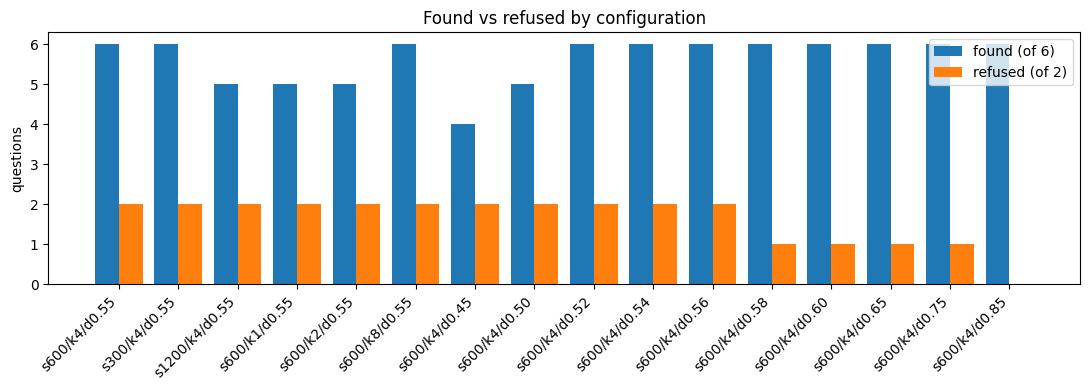

In [10]:
labels = ["s%d/k%d/d%.2f" % (r.chunk_size, r.k, r.max_distance) for r in df.itertuples()]
x = list(range(len(df)))
plt.figure(figsize=(11, 4))
plt.bar([i - 0.2 for i in x], df.found, width=0.4, label="found (of 6)")
plt.bar([i + 0.2 for i in x], df.refused, width=0.4, label="refused (of 2)")
plt.xticks(x, labels, rotation=45, ha="right")
plt.ylabel("questions")
plt.title("Found vs refused by configuration")
plt.legend()
plt.tight_layout()
plt.savefig("figure.png", dpi=150)
plt.show()

In [11]:
def per_question(chunk_size=600, overlap=100, k=4, max_distance=0.55):
    ch, src = [], []
    for path in my_files:
        pieces = split_into_chunks(open(path, encoding="utf-8").read(), chunk_size, overlap)
        ch += pieces
        src += [os.path.basename(path)] * len(pieces)
    col = build_collection(ch, src)
    row = {}
    for q in MY_GOLD:
        hits = retrieve(col, q["question"], k, max_distance)
        ok = found_evidence(hits, q["evidence"]) if q["answerable"] else (len(hits) == 0)
        row[q["qid"]] = "ok" if ok else "MISS"
    return row

pd.DataFrame({
    "base (s600,k4,d0.55)": per_question(),
    "size 300": per_question(chunk_size=300, overlap=50),
    "size 1200": per_question(chunk_size=1200, overlap=200),
    "k=1": per_question(k=1),
    "k=2": per_question(k=2),
    "d=0.45": per_question(max_distance=0.45),
    "d=0.50": per_question(max_distance=0.50),
    "d=0.60": per_question(max_distance=0.60),
})

,"base (s600,k4,d0.55)",size 300,size 1200,k=1,k=2,d=0.45,d=0.50,d=0.60
Q1,ok,ok,ok,MISS,MISS,MISS,MISS,ok
Q2,ok,ok,ok,ok,ok,ok,ok,ok
Q3,ok,ok,MISS,ok,ok,MISS,ok,ok
Q4,ok,ok,ok,ok,ok,ok,ok,ok
Q5,ok,ok,ok,ok,ok,ok,ok,ok
Q6,ok,ok,ok,ok,ok,ok,ok,ok
Q7,ok,ok,ok,ok,ok,ok,ok,ok
Q8,ok,ok,ok,ok,ok,ok,ok,MISS


In [12]:
q = next(x for x in MY_GOLD if x["qid"] == "Q1")
r = my_col.query(query_embeddings=embed([q["question"]]), n_results=6)
print("Q:", q["question"], "\n")
for d, dist, m in zip(r["documents"][0], r["distances"][0], r["metadatas"][0]):
    has = any(p.lower() in d.lower() for p in q["evidence"])
    print("%.3f" % dist, m["source"], "<-- HAS EVIDENCE" if has else "", "|", d[:110].replace("\n", " "))

Q: How quickly must an employee report a suspicious email? 

0.410 05_metrics_and_improvement.md  | le within 24 hours. An employee who clicks three simulated emails within 12 months has a conversation with the
0.412 05_metrics_and_improvement.md  | y reported emails turn out to be safe, and it is used to tune the Report Phish button messaging.  The team mee
0.446 01_reporting.md  | s. The security team aims to send the reporter a verdict of malicious, spam, or safe within 4 business hours. 
0.504 01_reporting.md <-- HAS EVIDENCE | # Reporting a Suspected Phishing Email  Northwind Logistics employees must report any suspicious email within 
0.506 03_containment.md  | # Containment and Cleanup  Once an email is confirmed malicious, the first action is to remove every copy from
0.543 01_reporting.md  | ysts need for investigation.  Employees must not click links, open attachments, or reply to the sender before 


---

## What to write up

The tables and charts above are the evidence. The report and the video are where you explain them.
See `MiniProject_RAG.md` for the full requirements. In short:

- Explain the complete RAG system in your own words: chunking, embeddings, the vector store, retrieval,
  augmentation, and generation, and where each one appears in your notebook.
- Describe the data you created and the questions you wrote, and why you chose the question your
  documents cannot answer.
- Report what your experiments showed: which setting changed your numbers most, what you would use, and
  whether anything found more answers while refusing less.
- Pick one question your RAG got wrong, look at the chunk it retrieved instead, and explain the mistake.

Submit one PDF report with the link to your GitHub project folder and the link to your video on its first
page. The notebook, `my_kb/`, `goldset.json`, `results.csv`, and your chart live in the repository, which
is private, with your instructor and the TA added as collaborators. The notebook must be committed with
its outputs showing.